# COCO Dataset Exploration & Preprocessing
Quick pipeline to stream COCO samples, flatten object annotations, visualize bounding boxes, and export to Parquet.


## Dataset Overview & Schema

- **Source Used for Analysis:** Hugging Face [`detection-datasets/coco`](https://huggingface.co/datasets/detection-datasets/coco) (streaming train split)
- **Where to Get Full Dataset Later:** Official COCO download page: [https://cocodataset.org/#download](https://cocodataset.org/#download)
- **Full Dataset Size:** ~27 GB compressed (~118k train + 5k val + 41k test images = ~164k images; annotations ~241 MB)
- **Classes:** 80 standard COCO object categories (e.g., person, car, dog, bowl, etc.)

### 1. Raw Dataset Schema (1 row per image)
When streamed from Hugging Face, each record represents an image containing all its annotated objects:

| Column | Type | Description |
| :--- | :--- | :--- |
| `image_id` | `int` | Unique COCO image identifier. |
| `image` | `PIL.JpegImageFile` | Decoded RGB image object. |
| `width` | `int` | Image width in pixels. |
| `height` | `int` | Image height in pixels. |
| `objects` | `dict` | Nested dictionary containing parallel lists of all bounding boxes in the image: |
| ↳ `bbox_id` | `list[int]` | Unique identifier for each bounding box annotation. |
| ↳ `category` | `list[int]` | Numeric category ID ($0$ to $79$). |
| ↳ `bbox` | `list[list[float]]` | Bounding box coordinates formatted as `[x_min, y_min, x_max, y_max]`. |
| ↳ `area` | `list[float]` | Bounding box area in square pixels ($width \times height$). |

### 2. Exploded Dataset Schema (1 row per object)
After flattening the nested `objects` dictionary for object-level detection and segmentation pipelines:

| Column | Type | Description |
| :--- | :--- | :--- |
| `image_id` | `int` | Parent image identifier. |
| `image` / `image_bytes` | `PIL.Image` / `bytes` | Full image (or compressed JPEG byte stream for Parquet serialization). |
| `width`, `height` | `int` | Parent image dimensions in pixels. |
| `bbox_id` | `int` | Unique bounding box annotation ID. |
| `category` | `str` | Human-readable COCO class name (e.g., `'bowl'`, `'broccoli'`, `'dog'`). |
| `bbox` | `list[float]` | Absolute coordinates `[x_min, y_min, x_max, y_max]`. |
| `area` | `float` | Area of the bounding box in pixels squared. |


### 1. Load dataset samples (streaming mode)


In [1]:
from datasets import load_dataset

# Stream 50 samples from COCO train split (no full dataset download needed)
ds_stream = load_dataset("detection-datasets/coco", split="train", streaming=True)
small_samples = list(ds_stream.take(50))


README.md:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

C:\Users\exe\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:137: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\exe\.cache\huggingface\hub\datasets--detection-datasets--coco. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

dataset_infos.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

### 2. Inspect raw data schema


In [2]:
import pandas as pd

# Load samples into DataFrame (1 row per image, nested 'objects' column)
df = pd.DataFrame(small_samples)
print(df.shape)
df.head()


(50, 5)


,image_id,image,width,height,objects
0,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,"{'bbox_id': [1038967, 1039564, 1058555, 153414..."
1,25,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,426,"{'bbox_id': [598548, 599491], 'category': [23,..."
2,30,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,428,"{'bbox_id': [291613, 1155486], 'category': [58..."
3,34,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,425,"{'bbox_id': [589229], 'category': [22], 'bbox'..."
4,36,<PIL.JpegImagePlugin.JpegImageFile image mode=...,481,640,"{'bbox_id': [284996, 453991], 'category': [25,..."


### 3. Flatten (explode) nested object annotations


In [3]:
import json
import ast
import pandas as pd

def to_dict(val):
    """Parse object annotations into a dictionary if needed."""
    if isinstance(val, dict):
        return val
    if isinstance(val, str):
        s = val.strip()
        if not s or s.lower() in {"nan", "none", "null"}:
            return None
        try:
            return json.loads(s)
        except json.JSONDecodeError:
            return ast.literal_eval(s)
    return None

# Parse annotations into dicts
dicts = df["objects"].apply(to_dict)

# Flatten nested lists into individual rows
parts = []
for idx, d in dicts.items():
    if isinstance(d, dict) and len(d) > 0:
        part = pd.DataFrame(d)
        part["_orig_idx"] = idx
        parts.append(part)

exploded_objs = pd.concat(parts, ignore_index=True)

# Merge back parent image columns (image_id, image, width, height)
parent = df.drop(columns=["objects"]).reset_index().rename(columns={"index": "_orig_idx"})
df = parent.merge(exploded_objs, on="_orig_idx", how="inner").drop(columns=["_orig_idx"])


In [4]:
# Flattened DataFrame: 1 row per bounding box
df


,image_id,image,width,height,bbox_id,category,bbox,area
0,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1038967,45,"[1.08, 187.69, 612.6700000000001, 473.53]",120057.13925
1,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1039564,45,"[311.73, 4.31, 631.01, 232.99]",44434.75110
2,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1058555,50,"[249.6, 229.27, 565.84, 474.35]",49577.94435
3,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1534147,45,"[0.0, 13.51, 434.48, 388.63]",24292.78170
4,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1913551,49,"[376.2, 40.36, 451.75, 86.89]",2239.29240
...,...,...,...,...,...,...,...,...
423,308,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,426,2075186,25,"[276.24, 63.14, 363.85, 137.7]",1198.25465
424,309,<PIL.JpegImagePlugin.JpegImageFile image mode=...,600,600,1161269,77,"[153.18, 213.25, 287.75, 426.27]",17341.16930
425,309,<PIL.JpegImagePlugin.JpegImageFile image mode=...,600,600,1162241,77,"[273.71, 214.38, 391.01, 355.96000000000004]",12334.02410
426,309,<PIL.JpegImagePlugin.JpegImageFile image mode=...,600,600,1816964,16,"[420.15, 71.45, 512.98, 195.10000000000002]",4310.30720


### 4. Map category IDs to class names


In [5]:
# Map numeric category IDs to COCO class names
class_label = ds_stream.features["objects"]["category"].feature
id2label = {idx: name for idx, name in enumerate(class_label.names)}
df["category"] = df["category"].map(id2label)
df


,image_id,image,width,height,bbox_id,category,bbox,area
0,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1038967,bowl,"[1.08, 187.69, 612.6700000000001, 473.53]",120057.13925
1,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1039564,bowl,"[311.73, 4.31, 631.01, 232.99]",44434.75110
2,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1058555,broccoli,"[249.6, 229.27, 565.84, 474.35]",49577.94435
3,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1534147,bowl,"[0.0, 13.51, 434.48, 388.63]",24292.78170
4,9,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,480,1913551,orange,"[376.2, 40.36, 451.75, 86.89]",2239.29240
...,...,...,...,...,...,...,...,...
423,308,<PIL.JpegImagePlugin.JpegImageFile image mode=...,640,426,2075186,umbrella,"[276.24, 63.14, 363.85, 137.7]",1198.25465
424,309,<PIL.JpegImagePlugin.JpegImageFile image mode=...,600,600,1161269,teddy bear,"[153.18, 213.25, 287.75, 426.27]",17341.16930
425,309,<PIL.JpegImagePlugin.JpegImageFile image mode=...,600,600,1162241,teddy bear,"[273.71, 214.38, 391.01, 355.96000000000004]",12334.02410
426,309,<PIL.JpegImagePlugin.JpegImageFile image mode=...,600,600,1816964,dog,"[420.15, 71.45, 512.98, 195.10000000000002]",4310.30720


### 5. Visualize ground-truth bounding boxes


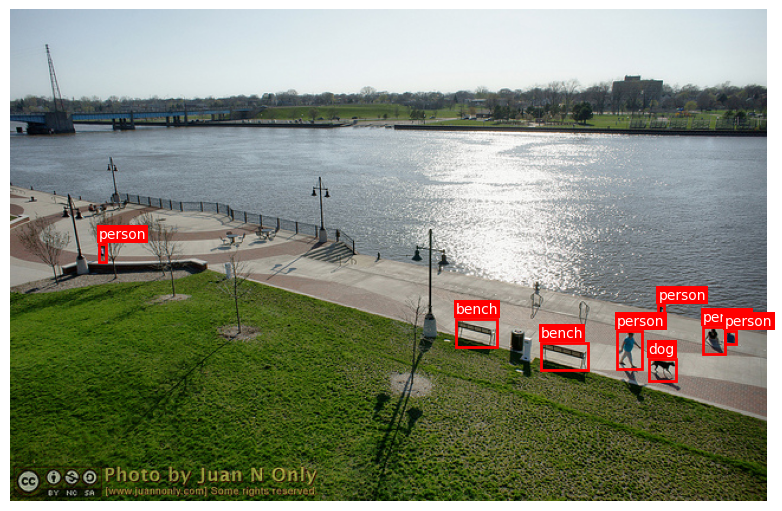

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import random


def format_category(category, category_map=None, fallback="unlabeled"):
    if pd.isna(category):
        return fallback
    if isinstance(category, float) and category.is_integer():
        category = int(category)
    if category_map is not None:
        return str(category_map.get(category, category))
    return str(category)


def show_objects(df, image_id, category_map=None, fallback="unlabeled"):
    """Draw bounding boxes [x_min, y_min, x_max, y_max] and labels on image."""
    filtered_df = df[df["image_id"] == image_id]
    if filtered_df.empty:
        print(f"No rows found for image_id={image_id}")
        return

    image = filtered_df["image"].iloc[0]
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(image)

    for _, row in filtered_df.iterrows():
        bbox = row["bbox"]
        if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
            continue

        x_min, y_min, x_max, y_max = bbox
        rect = plt.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
        ax.add_patch(rect)

        label = format_category(row["category"], category_map=category_map, fallback=fallback)
        ax.text(
            x_min,
            max(y_min - 5, 0),
            label,
            color="white",
            fontsize=10,
            bbox=dict(facecolor="red", edgecolor="none", pad=1.5),
        )

    ax.axis("off")
    plt.tight_layout()
    plt.show()


# Visualize a random image
unique_image_ids = df["image_id"].unique()
show_objects(df, random.choice(unique_image_ids))


### 6. Save to Parquet (images as JPEG bytes)


In [10]:
import io
import pandas as pd
from PIL import Image


def pil_to_jpeg_bytes(img, quality=95):
    """Encode PIL image to JPEG bytes for Parquet compatibility."""
    if isinstance(img, Image.Image):
        buf = io.BytesIO()
        img.convert("RGB").save(buf, format="JPEG", quality=quality)
        return buf.getvalue()
    return None


def jpeg_bytes_to_pil(b):
    """Decode JPEG bytes back to PIL Image."""
    if isinstance(b, (bytes, bytearray)):
        return Image.open(io.BytesIO(b))
    return b


# Save DataFrame to Parquet with images stored as JPEG bytes
df_to_save = df.copy()
df_to_save["image_bytes"] = df_to_save["image"].apply(pil_to_jpeg_bytes)
df_to_save = df_to_save.drop(columns=["image"])
df_to_save.to_parquet("coco_data_example.parquet", index=False)


### 7. Verify Parquet round-trip


In [11]:
# Load Parquet file back and restore PIL images
loaded_df = pd.read_parquet("coco_data_example.parquet")
loaded_df["image"] = loaded_df["image_bytes"].apply(jpeg_bytes_to_pil)
loaded_df


,image_id,width,height,bbox_id,category,bbox,area,image_bytes,image
0,9,640,480,1038967,bowl,"[1.08, 187.69, 612.6700000000001, 473.53]",120057.13925,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
1,9,640,480,1039564,bowl,"[311.73, 4.31, 631.01, 232.99]",44434.75110,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
2,9,640,480,1058555,broccoli,"[249.6, 229.27, 565.84, 474.35]",49577.94435,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
3,9,640,480,1534147,bowl,"[0.0, 13.51, 434.48, 388.63]",24292.78170,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
4,9,640,480,1913551,orange,"[376.2, 40.36, 451.75, 86.89]",2239.29240,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
...,...,...,...,...,...,...,...,...,...
423,308,640,426,2075186,umbrella,"[276.24, 63.14, 363.85, 137.7]",1198.25465,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
424,309,600,600,1161269,teddy bear,"[153.18, 213.25, 287.75, 426.27]",17341.16930,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
425,309,600,600,1162241,teddy bear,"[273.71, 214.38, 391.01, 355.96000000000004]",12334.02410,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
426,309,600,600,1816964,dog,"[420.15, 71.45, 512.98, 195.10000000000002]",4310.30720,b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
